# Brain MRI Segmentation Project - Final Version with Affine Augmentation

In [3]:
!pip install tensorflow numpy pandas matplotlib opencv-python scikit-image scikit-learn tqdm albumentations

In [4]:

import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate, BatchNormalization, Activation, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
import albumentations as A


In [5]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

def preprocess_image(img_path, target_size=(256, 256), gray=False):
    img = cv2.imread(img_path)
    if gray:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)[..., np.newaxis]
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, target_size)
    return img / 255.0

augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(0.0, 0.05), rotate=(-10, 10), p=0.5),
    A.RandomBrightnessContrast(p=0.2),
])

def augment_image(image, mask):
    if np.random.rand() < 0.3:
        return img, mask
    augmented = augmentation(image=image, mask=mask)
    return augmented['image'], augmented['mask']

base_path = '/content/drive/MyDrive/kaggle_3m'

mask_paths = glob(os.path.join(base_path, '*/*_mask*'))
image_paths = [p.replace('_mask', '') for p in mask_paths]

X = []
Y = []
for img_p, mask_p in zip(image_paths, mask_paths):
    img = preprocess_image(img_p, (256, 256), gray=True)
    mask = preprocess_image(mask_p, (256, 256), gray=True)
    img, mask = augment_image(img, mask)
    X.append(img.astype('float32'))
    Y.append(mask.astype('float32'))

X = np.array(X)
Y = np.array(Y)
Y[Y >= 0.5] = 1
Y[Y < 0.5] = 0

X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)


In [7]:

def dice_coeff(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, 'float32'))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, 'float32'))
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coeff(y_true, y_pred)

def composite_loss(y_true, y_pred):
    bce = tf.keras.losses.BinaryCrossentropy()(y_true, y_pred)
    return 0.5 * bce + 0.5 * dice_loss(y_true, y_pred)


In [8]:

def unet_model(input_size=(256, 256, 1), dropout_rate=0.3):
    inputs = Input(input_size)

    def conv_block(x, filters):
        x = Conv2D(filters, (3, 3), padding="same")(x)
        x = BatchNormalization()(x)
        x = Activation("relu")(x)
        x = Conv2D(filters, (3, 3), padding="same")(x)
        x = BatchNormalization()(x)
        x = Activation("relu")(x)
        return x

    def encoder_block(x, filters):
        c = conv_block(x, filters)
        p = MaxPooling2D((2, 2))(c)
        p = Dropout(dropout_rate)(p)
        return c, p

    def decoder_block(x, skip, filters):
        u = Conv2DTranspose(filters, (2, 2), strides=(2, 2), padding="same")(x)
        u = concatenate([u, skip])
        u = Dropout(dropout_rate)(u)
        c = conv_block(u, filters)
        return c

    c1, p1 = encoder_block(inputs, 64)
    c2, p2 = encoder_block(p1, 128)
    c3, p3 = encoder_block(p2, 256)
    c4, p4 = encoder_block(p3, 512)

    bn = conv_block(p4, 1024)

    d1 = decoder_block(bn, c4, 512)
    d2 = decoder_block(d1, c3, 256)
    d3 = decoder_block(d2, c2, 128)
    d4 = decoder_block(d3, c1, 64)

    outputs = Conv2D(1, (1, 1), activation="sigmoid")(d4)

    return Model(inputs, outputs)


In [9]:

BATCH_SIZE = 8
EPOCHS = 50

model = unet_model()
model.compile(optimizer=Adam(learning_rate=1e-4), loss=composite_loss, metrics=[dice_coeff])

checkpoint = ModelCheckpoint("unet_mri_final_affine.keras", save_best_only=True, verbose=1)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1, min_lr=1e-6)
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

history = model.fit(
    X_train, Y_train,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    callbacks=[checkpoint, lr_scheduler, early_stopping]
)

model.save("unet_final_affine_saved.keras")
model.save("/content/drive/MyDrive/my_model.keras")


Epoch 1/50
393/393 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - dice_coeff: 0.0557 - loss: 0.5857
Epoch 1: val_loss improved from inf to 0.53399, saving model to unet_mri_final_affine.keras
393/393 ━━━━━━━━━━━━━━━━━━━━ 198s 361ms/step - dice_coeff: 0.0558 - loss: 0.5855 - val_dice_coeff: 0.0214 - val_loss: 0.5340 - learning_rate: 1.0000e-04
Epoch 2/50
393/393 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - dice_coeff: 0.1726 - loss: 0.4514
Epoch 2: val_loss improved from 0.53399 to 0.52578, saving model to unet_mri_final_affine.keras
393/393 ━━━━━━━━━━━━━━━━━━━━ 98s 249ms/step - dice_coeff: 0.1727 - loss: 0.4513 - val_dice_coeff: 0.1843 - val_loss: 0.5258 - learning_rate: 1.0000e-04
Epoch 3/50
393/393 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - dice_coeff: 0.3157 - loss: 0.3680
Epoch 3: val_loss improved from 0.52578 to 0.32370, saving model to unet_mri_final_affine.keras
393/393 ━━━━━━━━━━━━━━━━━━━━ 97s 248ms/step - dice_coeff: 0.3158 - loss: 0.3679 - val_dice_coeff: 0.3976 - val_loss: 0.3237 - learning_rate: 

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


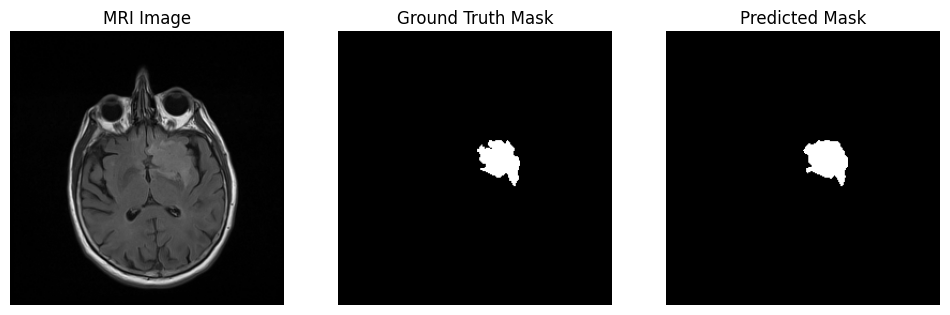

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


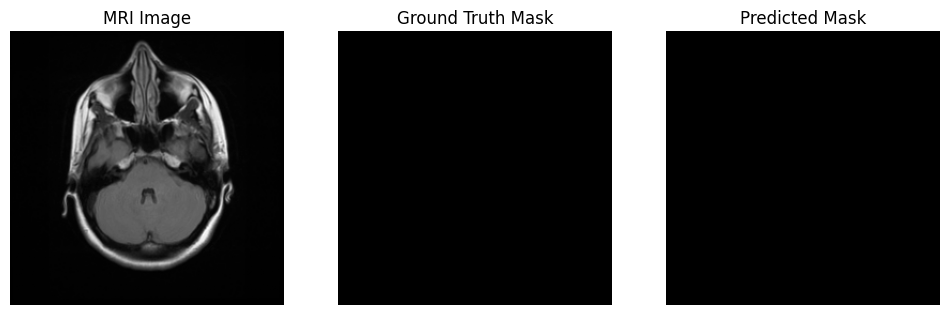

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


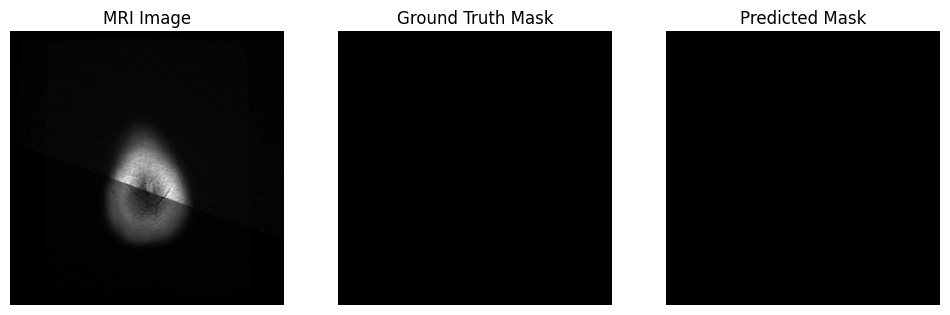

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


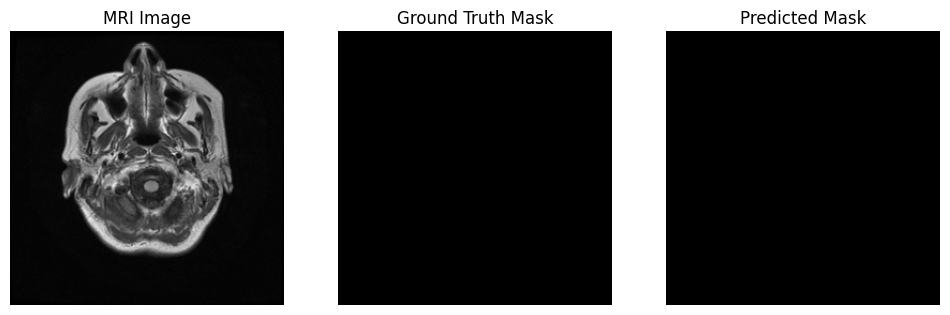

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


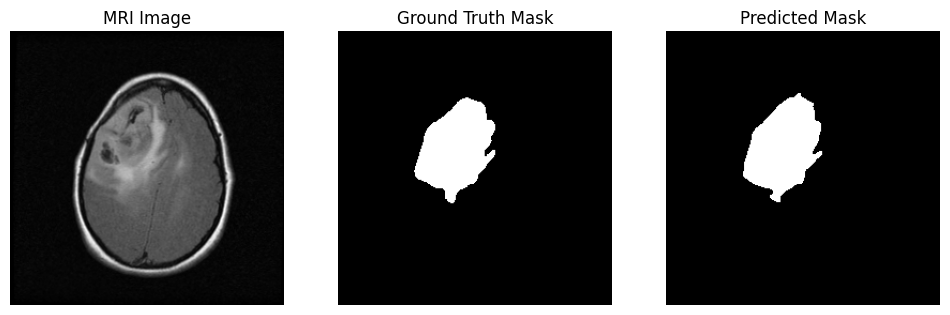

In [10]:

import random

idx = random.sample(range(len(X_val)), 5)

for i in idx:
    img = X_val[i]
    mask = Y_val[i]
    pred = model.predict(np.expand_dims(img, axis=0))[0]

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(img.squeeze(), cmap='gray')
    plt.title('MRI Image')
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(mask.squeeze(), cmap='gray')
    plt.title('Ground Truth Mask')
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(pred.squeeze() > 0.5, cmap='gray')
    plt.title('Predicted Mask')
    plt.axis('off')

    plt.show()
